# CASB visual mechanisms
Original counterparts to the specified UGO figures. See Visual_Mechanism_Captions.md for the reference mapping, captions and proposed overlap/noise experiment. Synthetic examples illustrate mechanisms and are not benchmark performance claims.

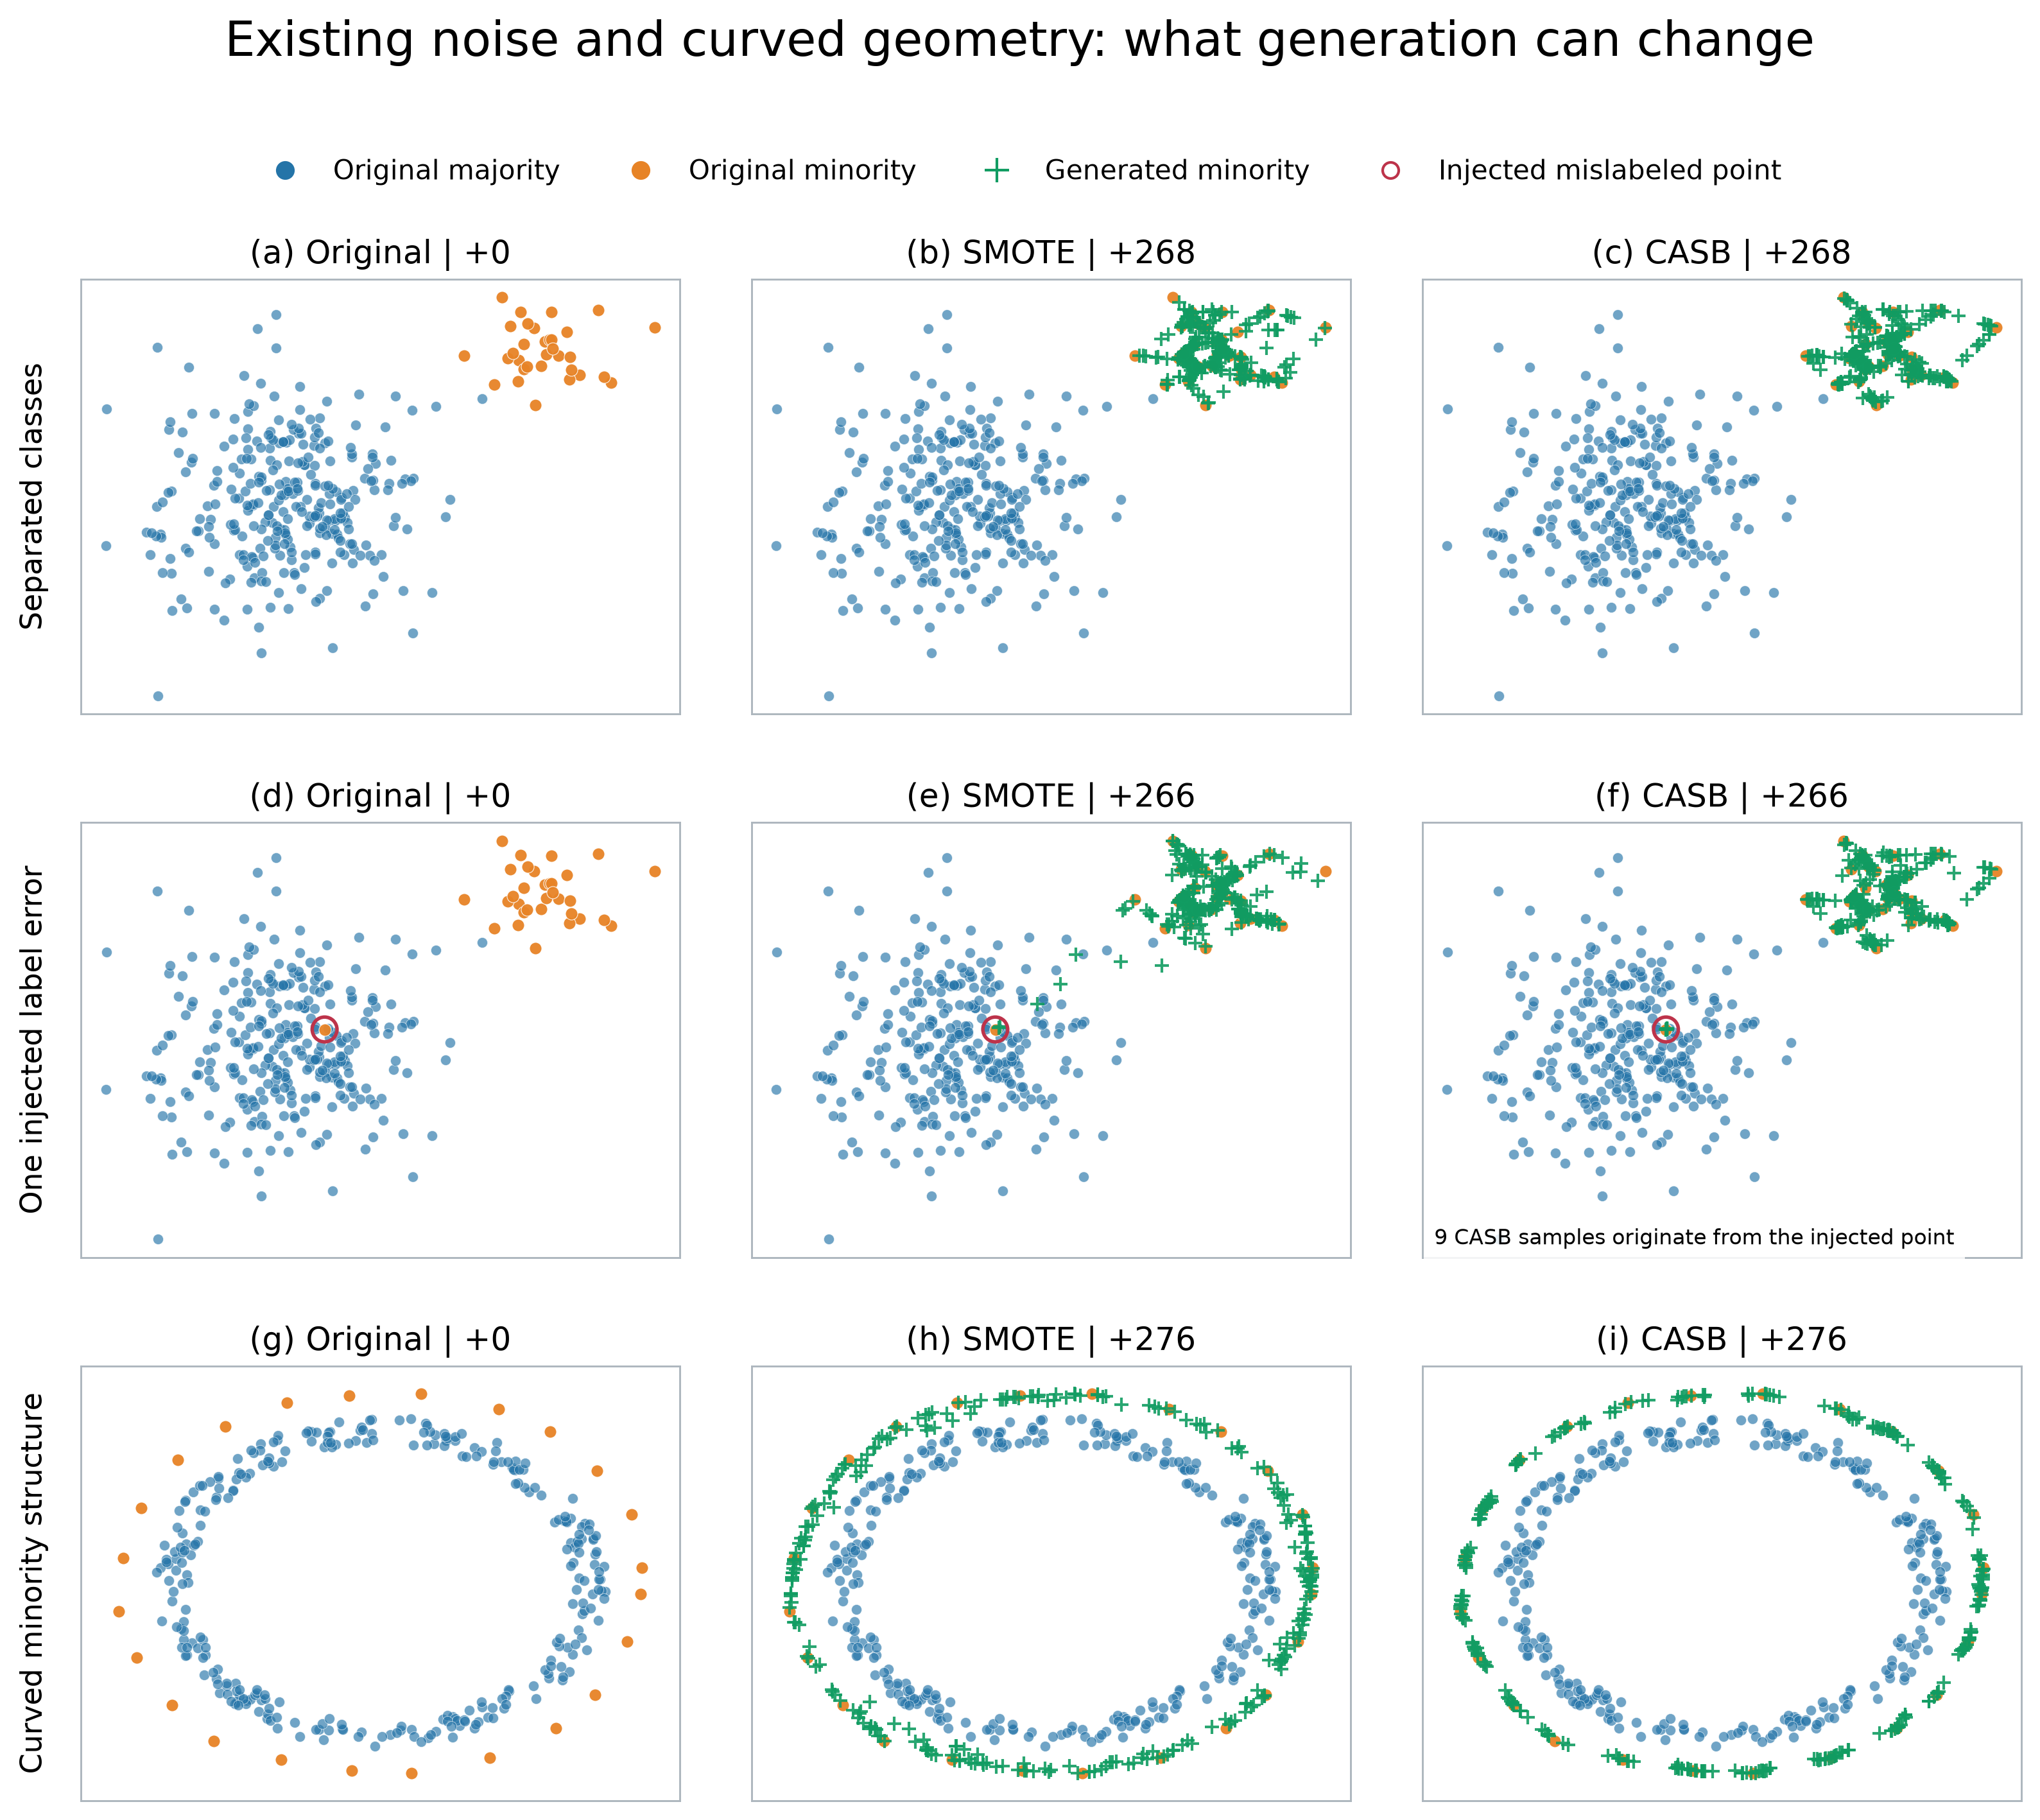

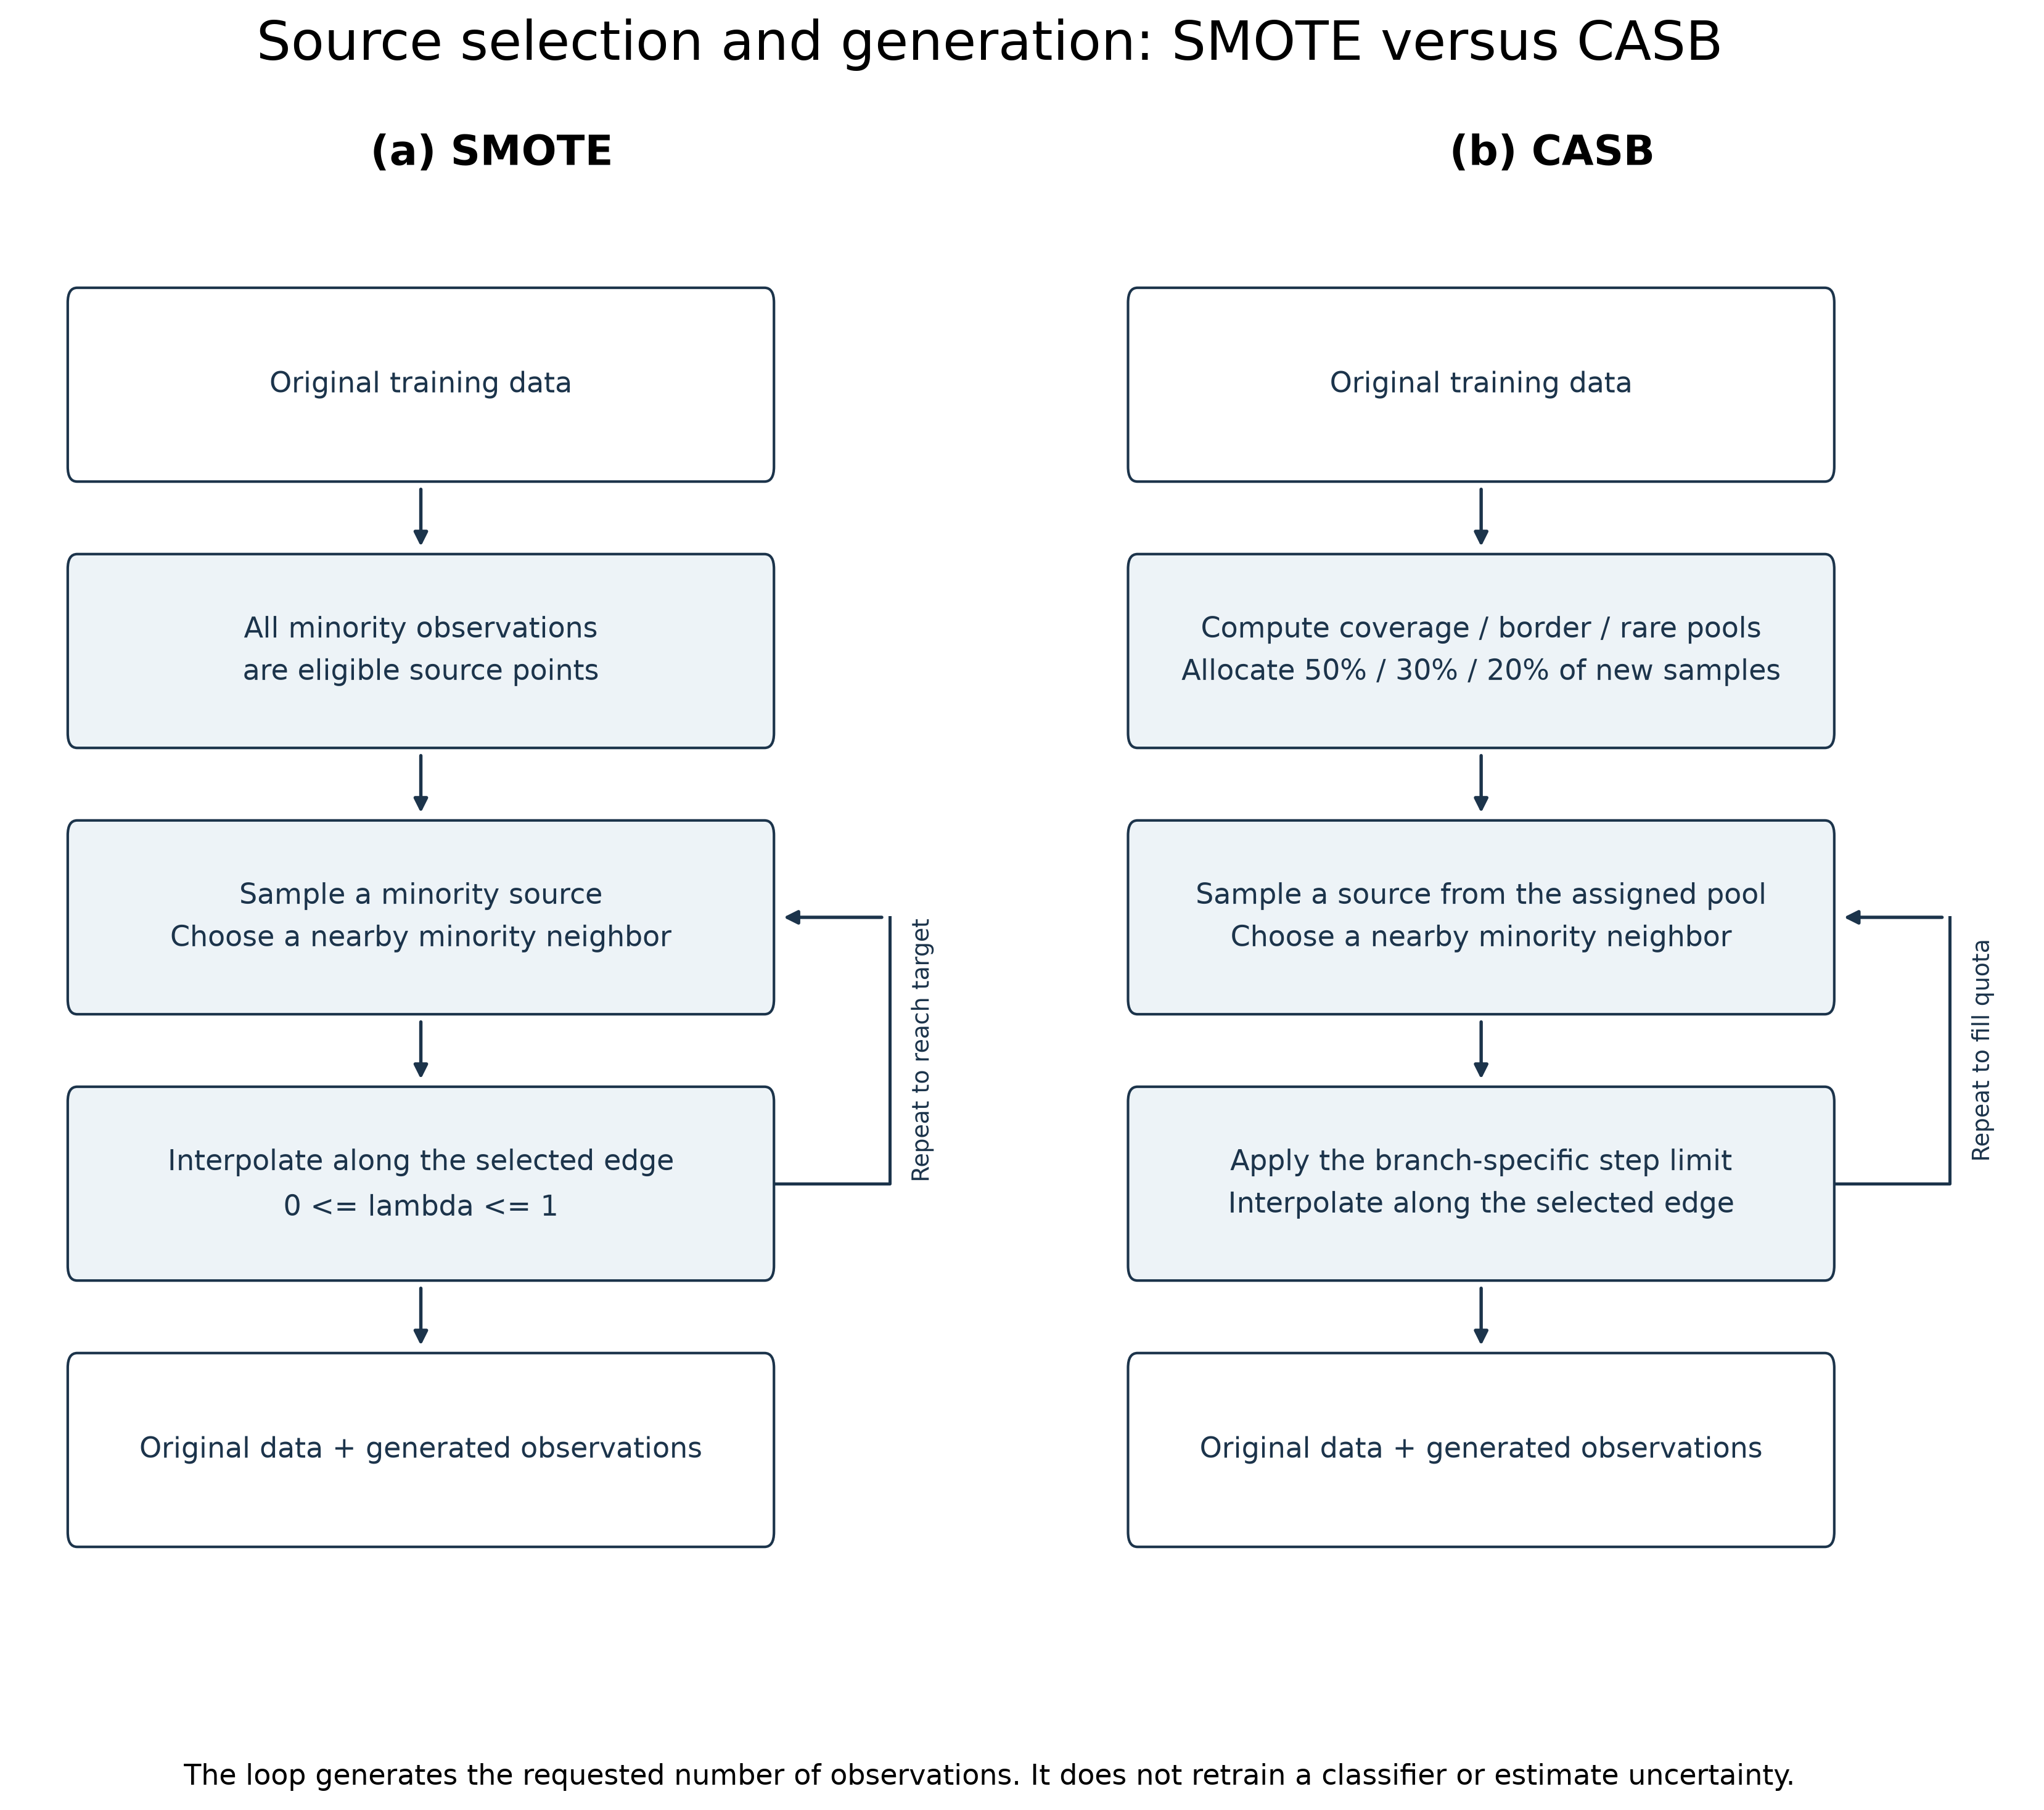

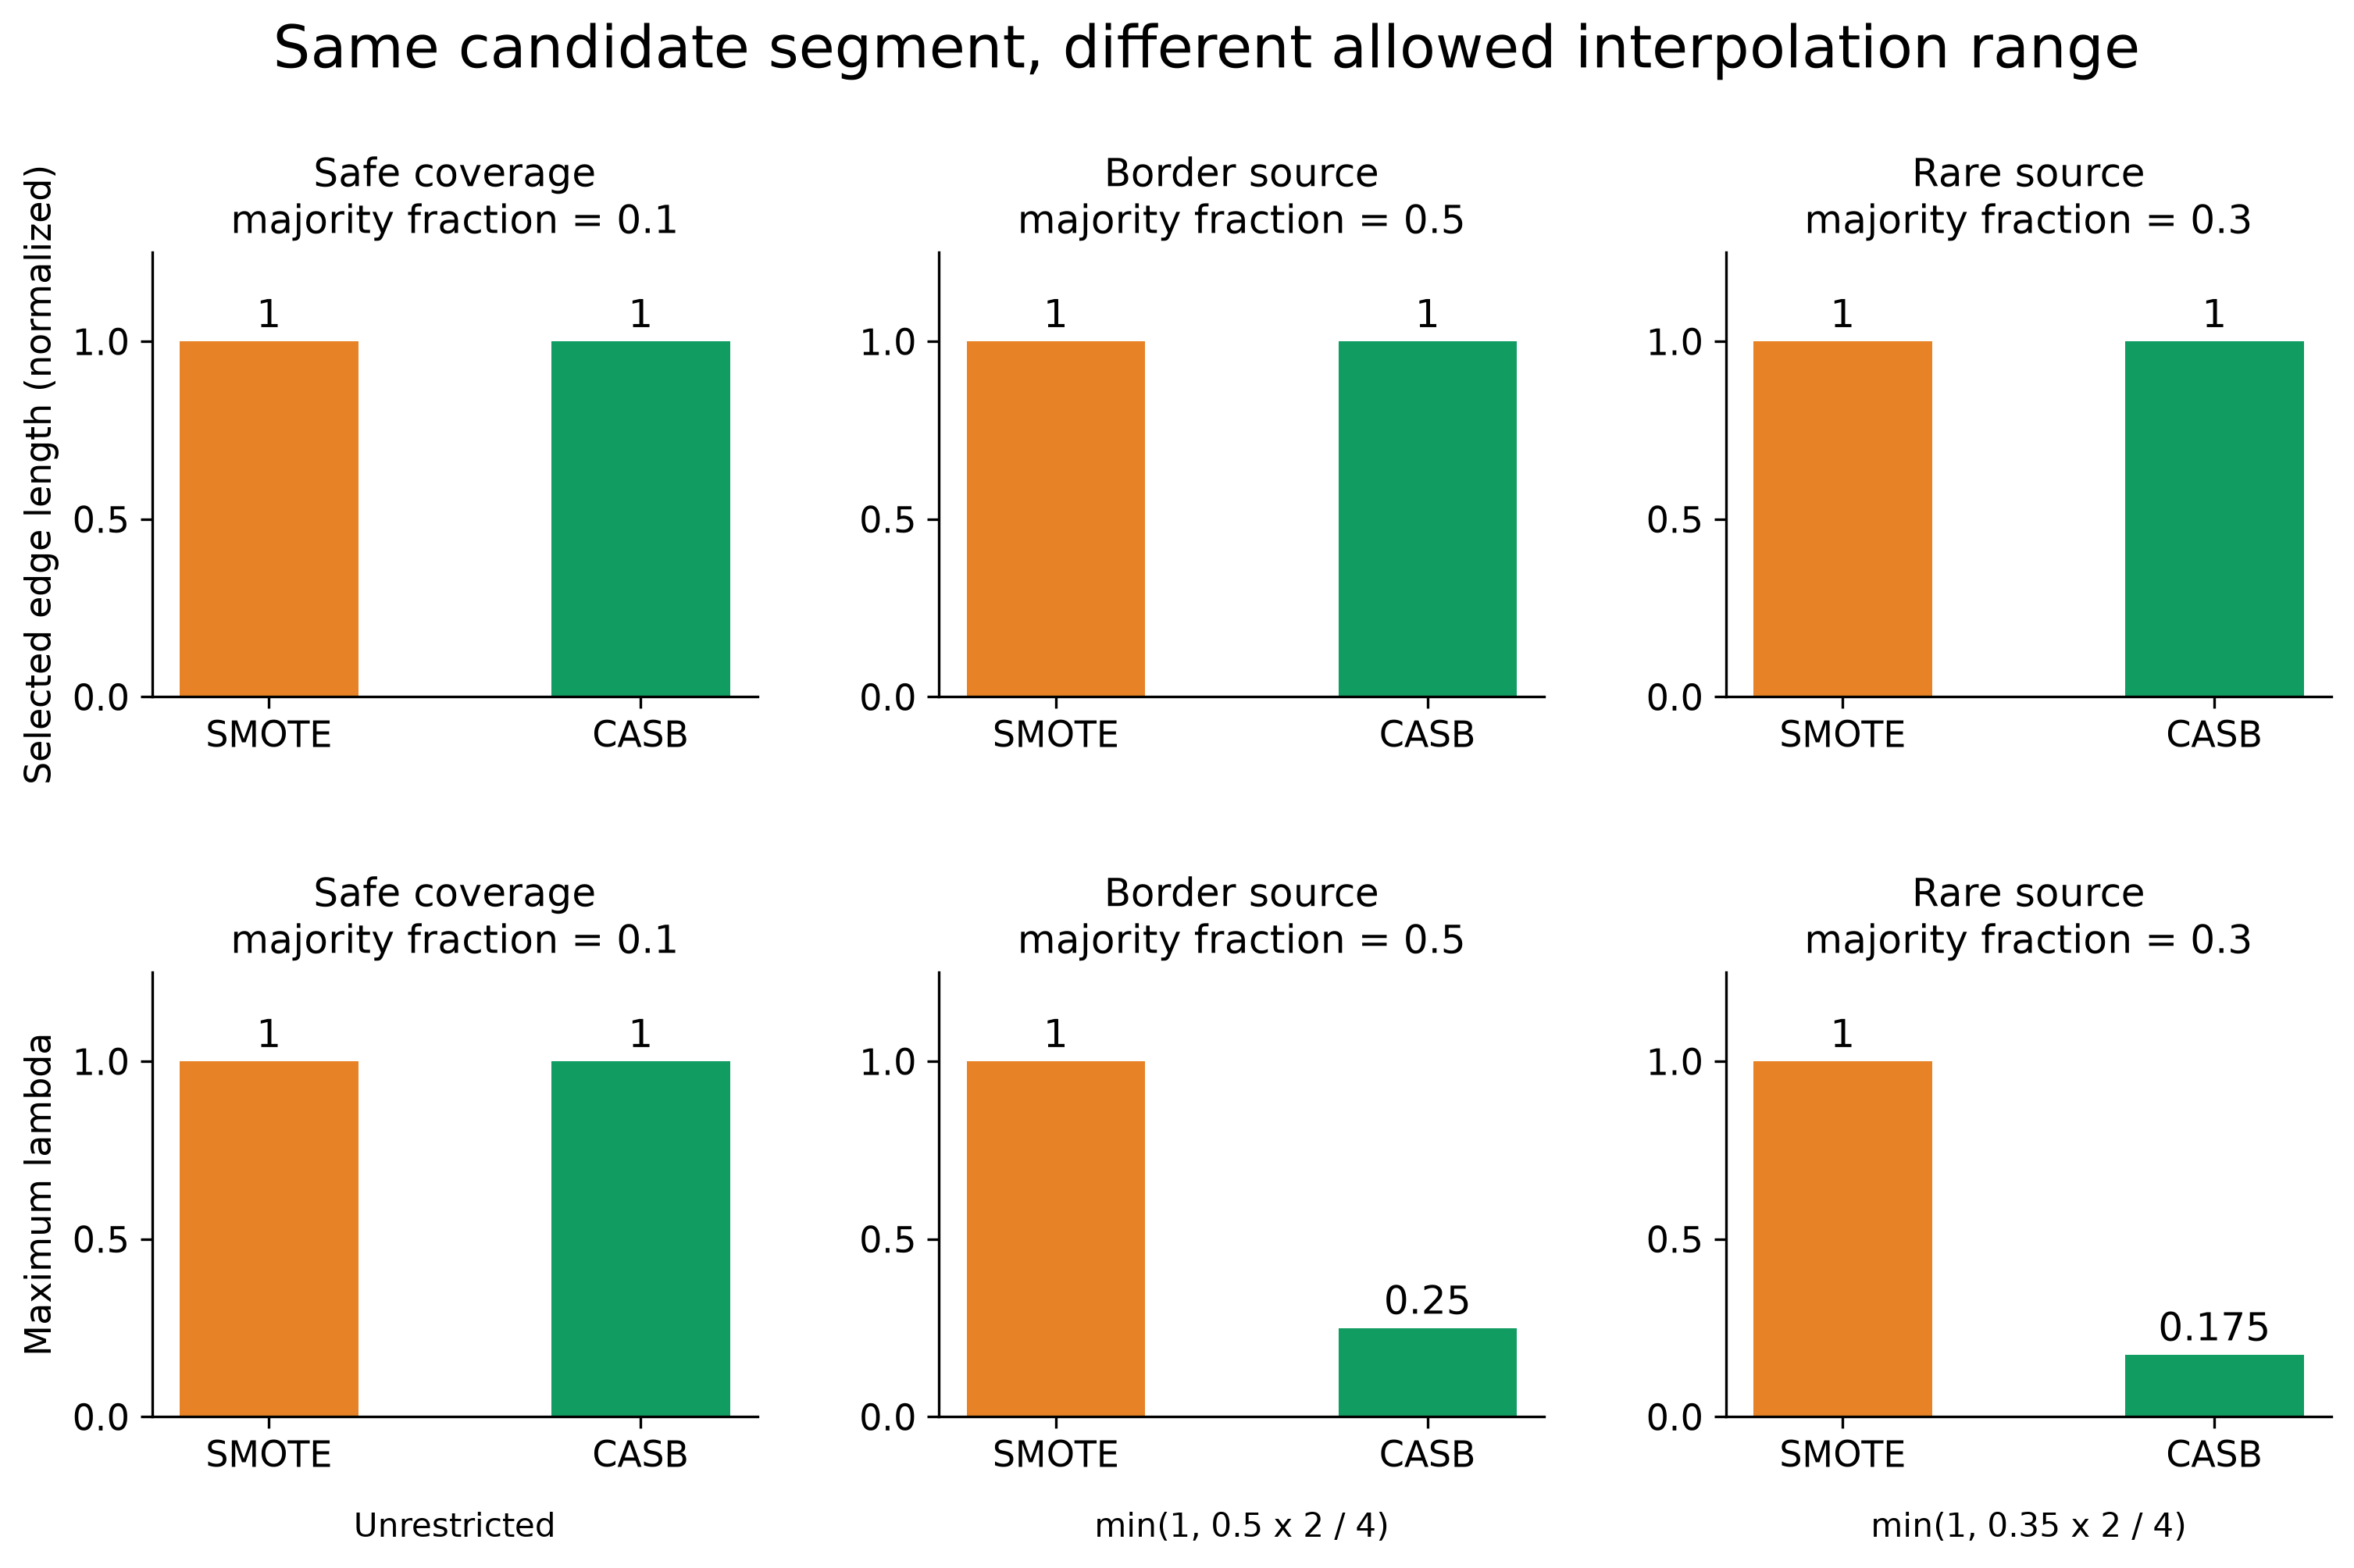

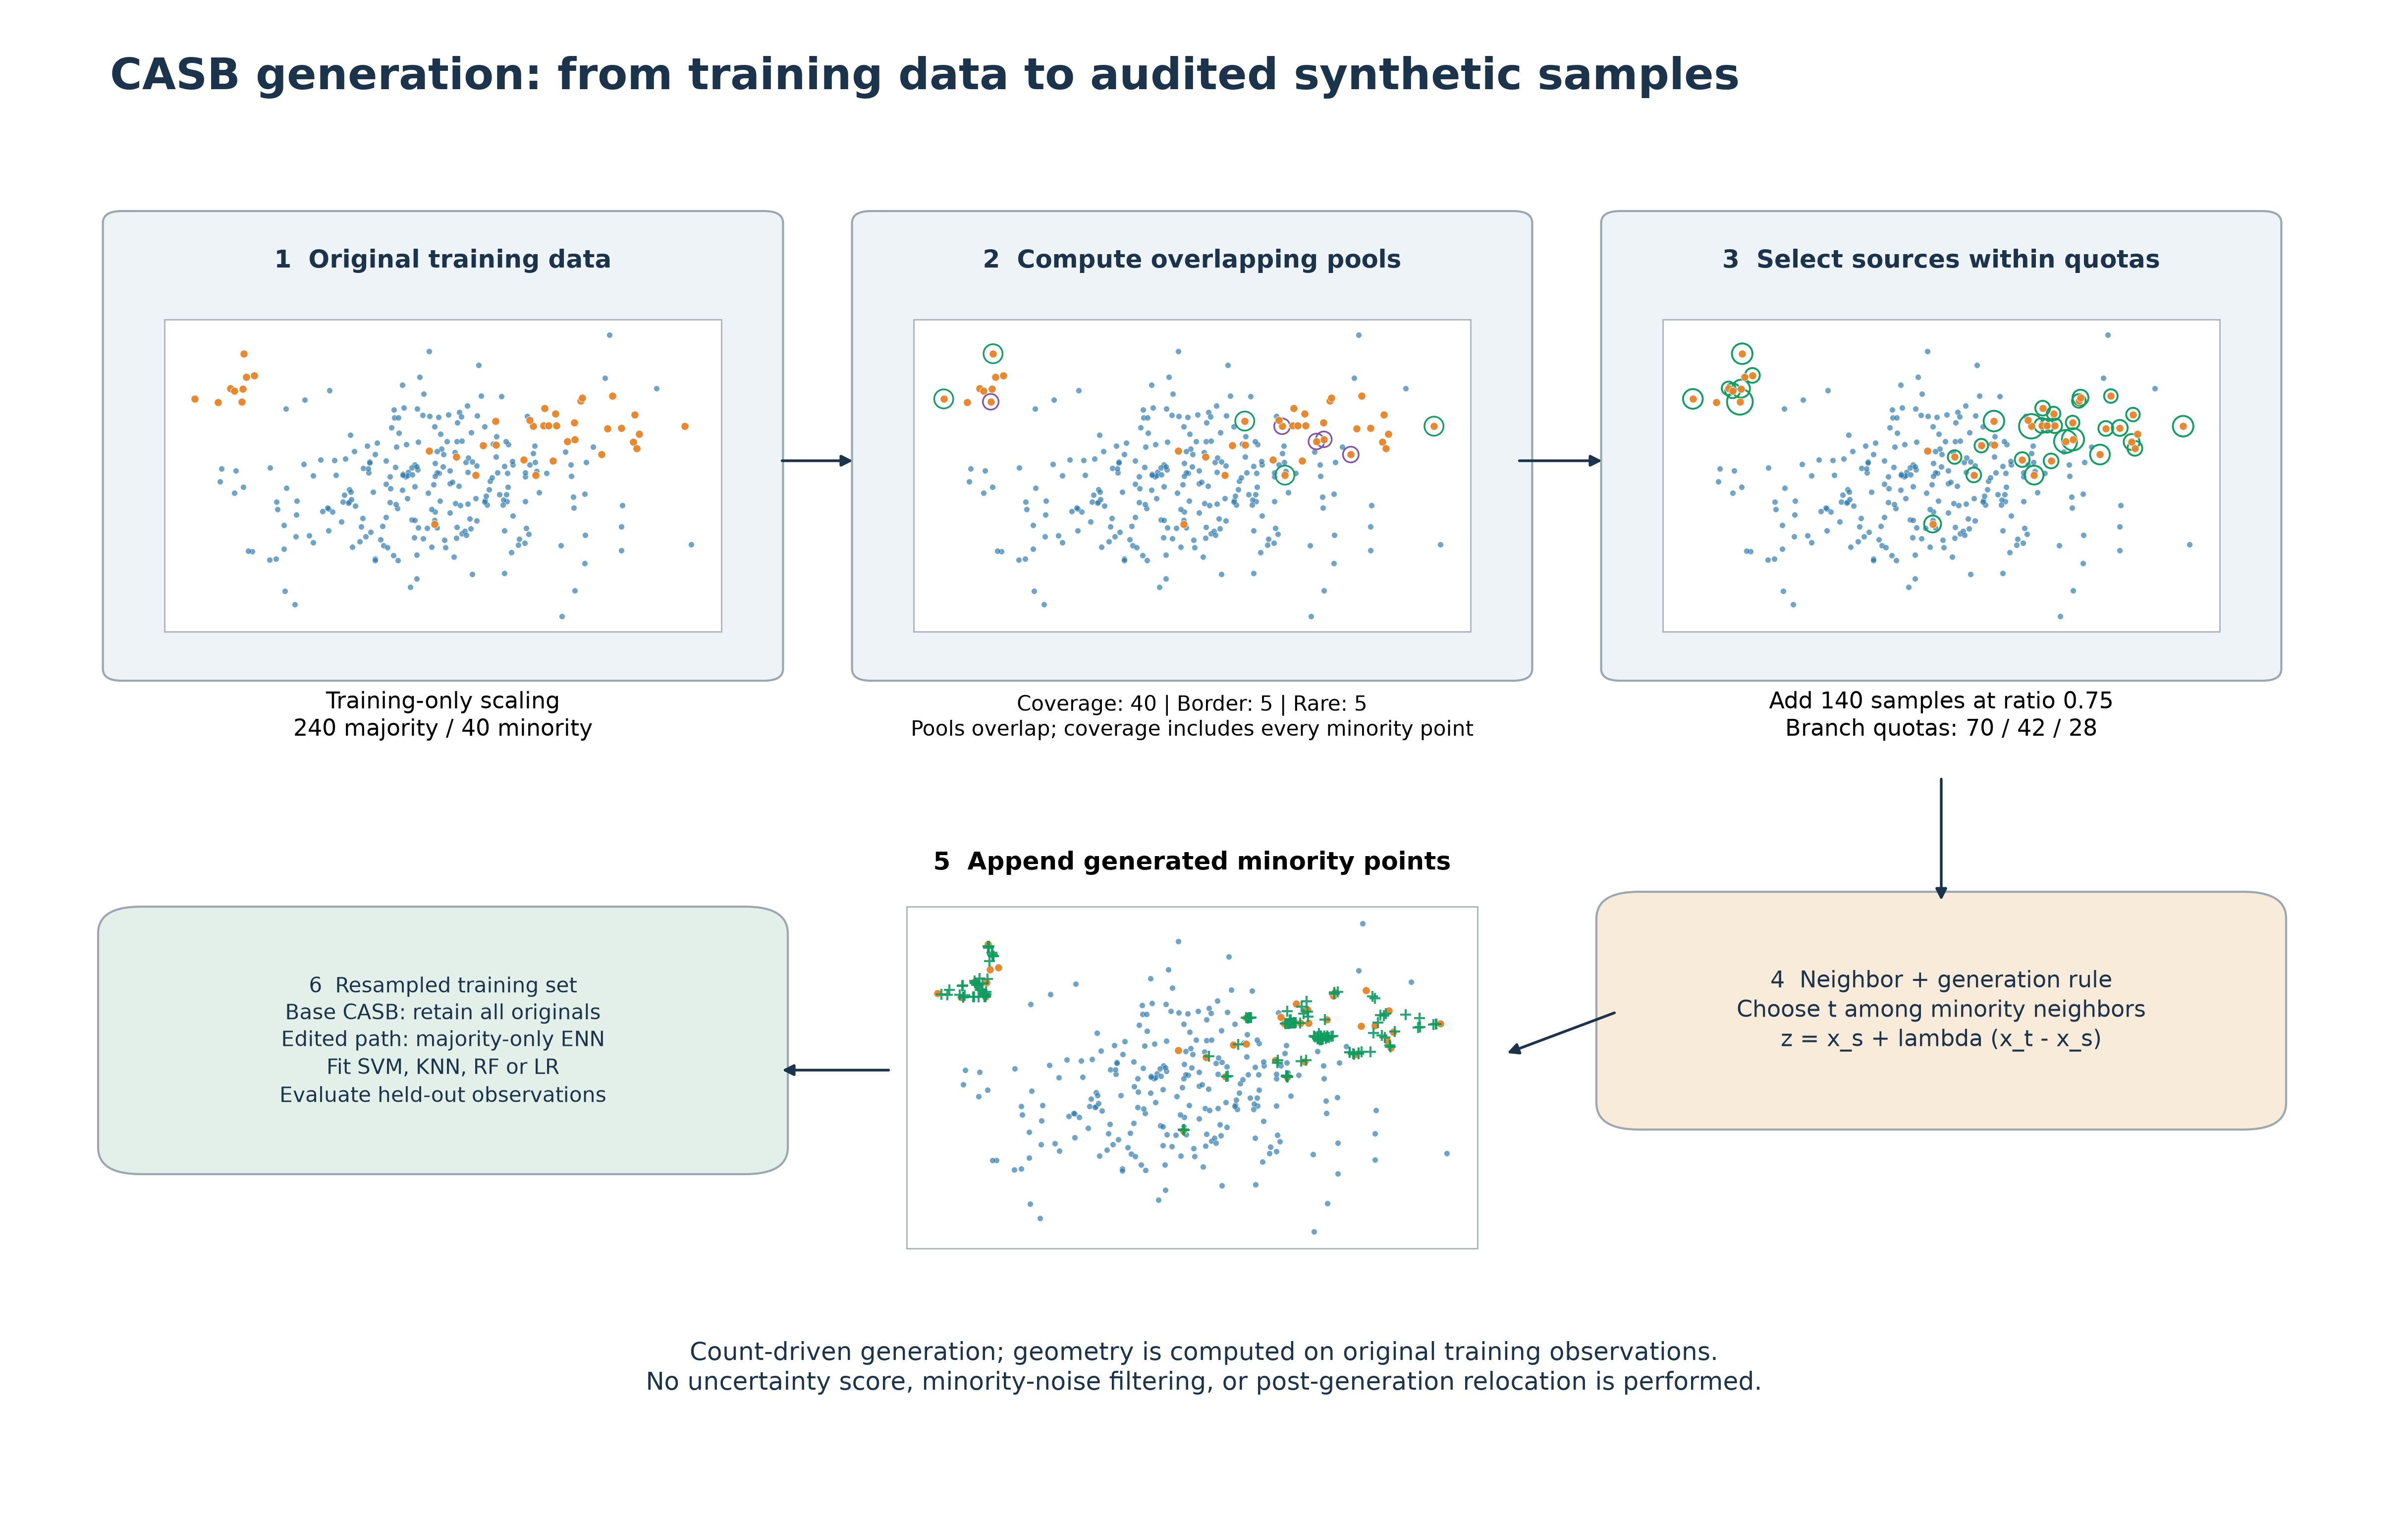

,zoom_event,source_id,neighbor_id,lambda,lambda_limit
0,70,243,266,0.31143,0.634655


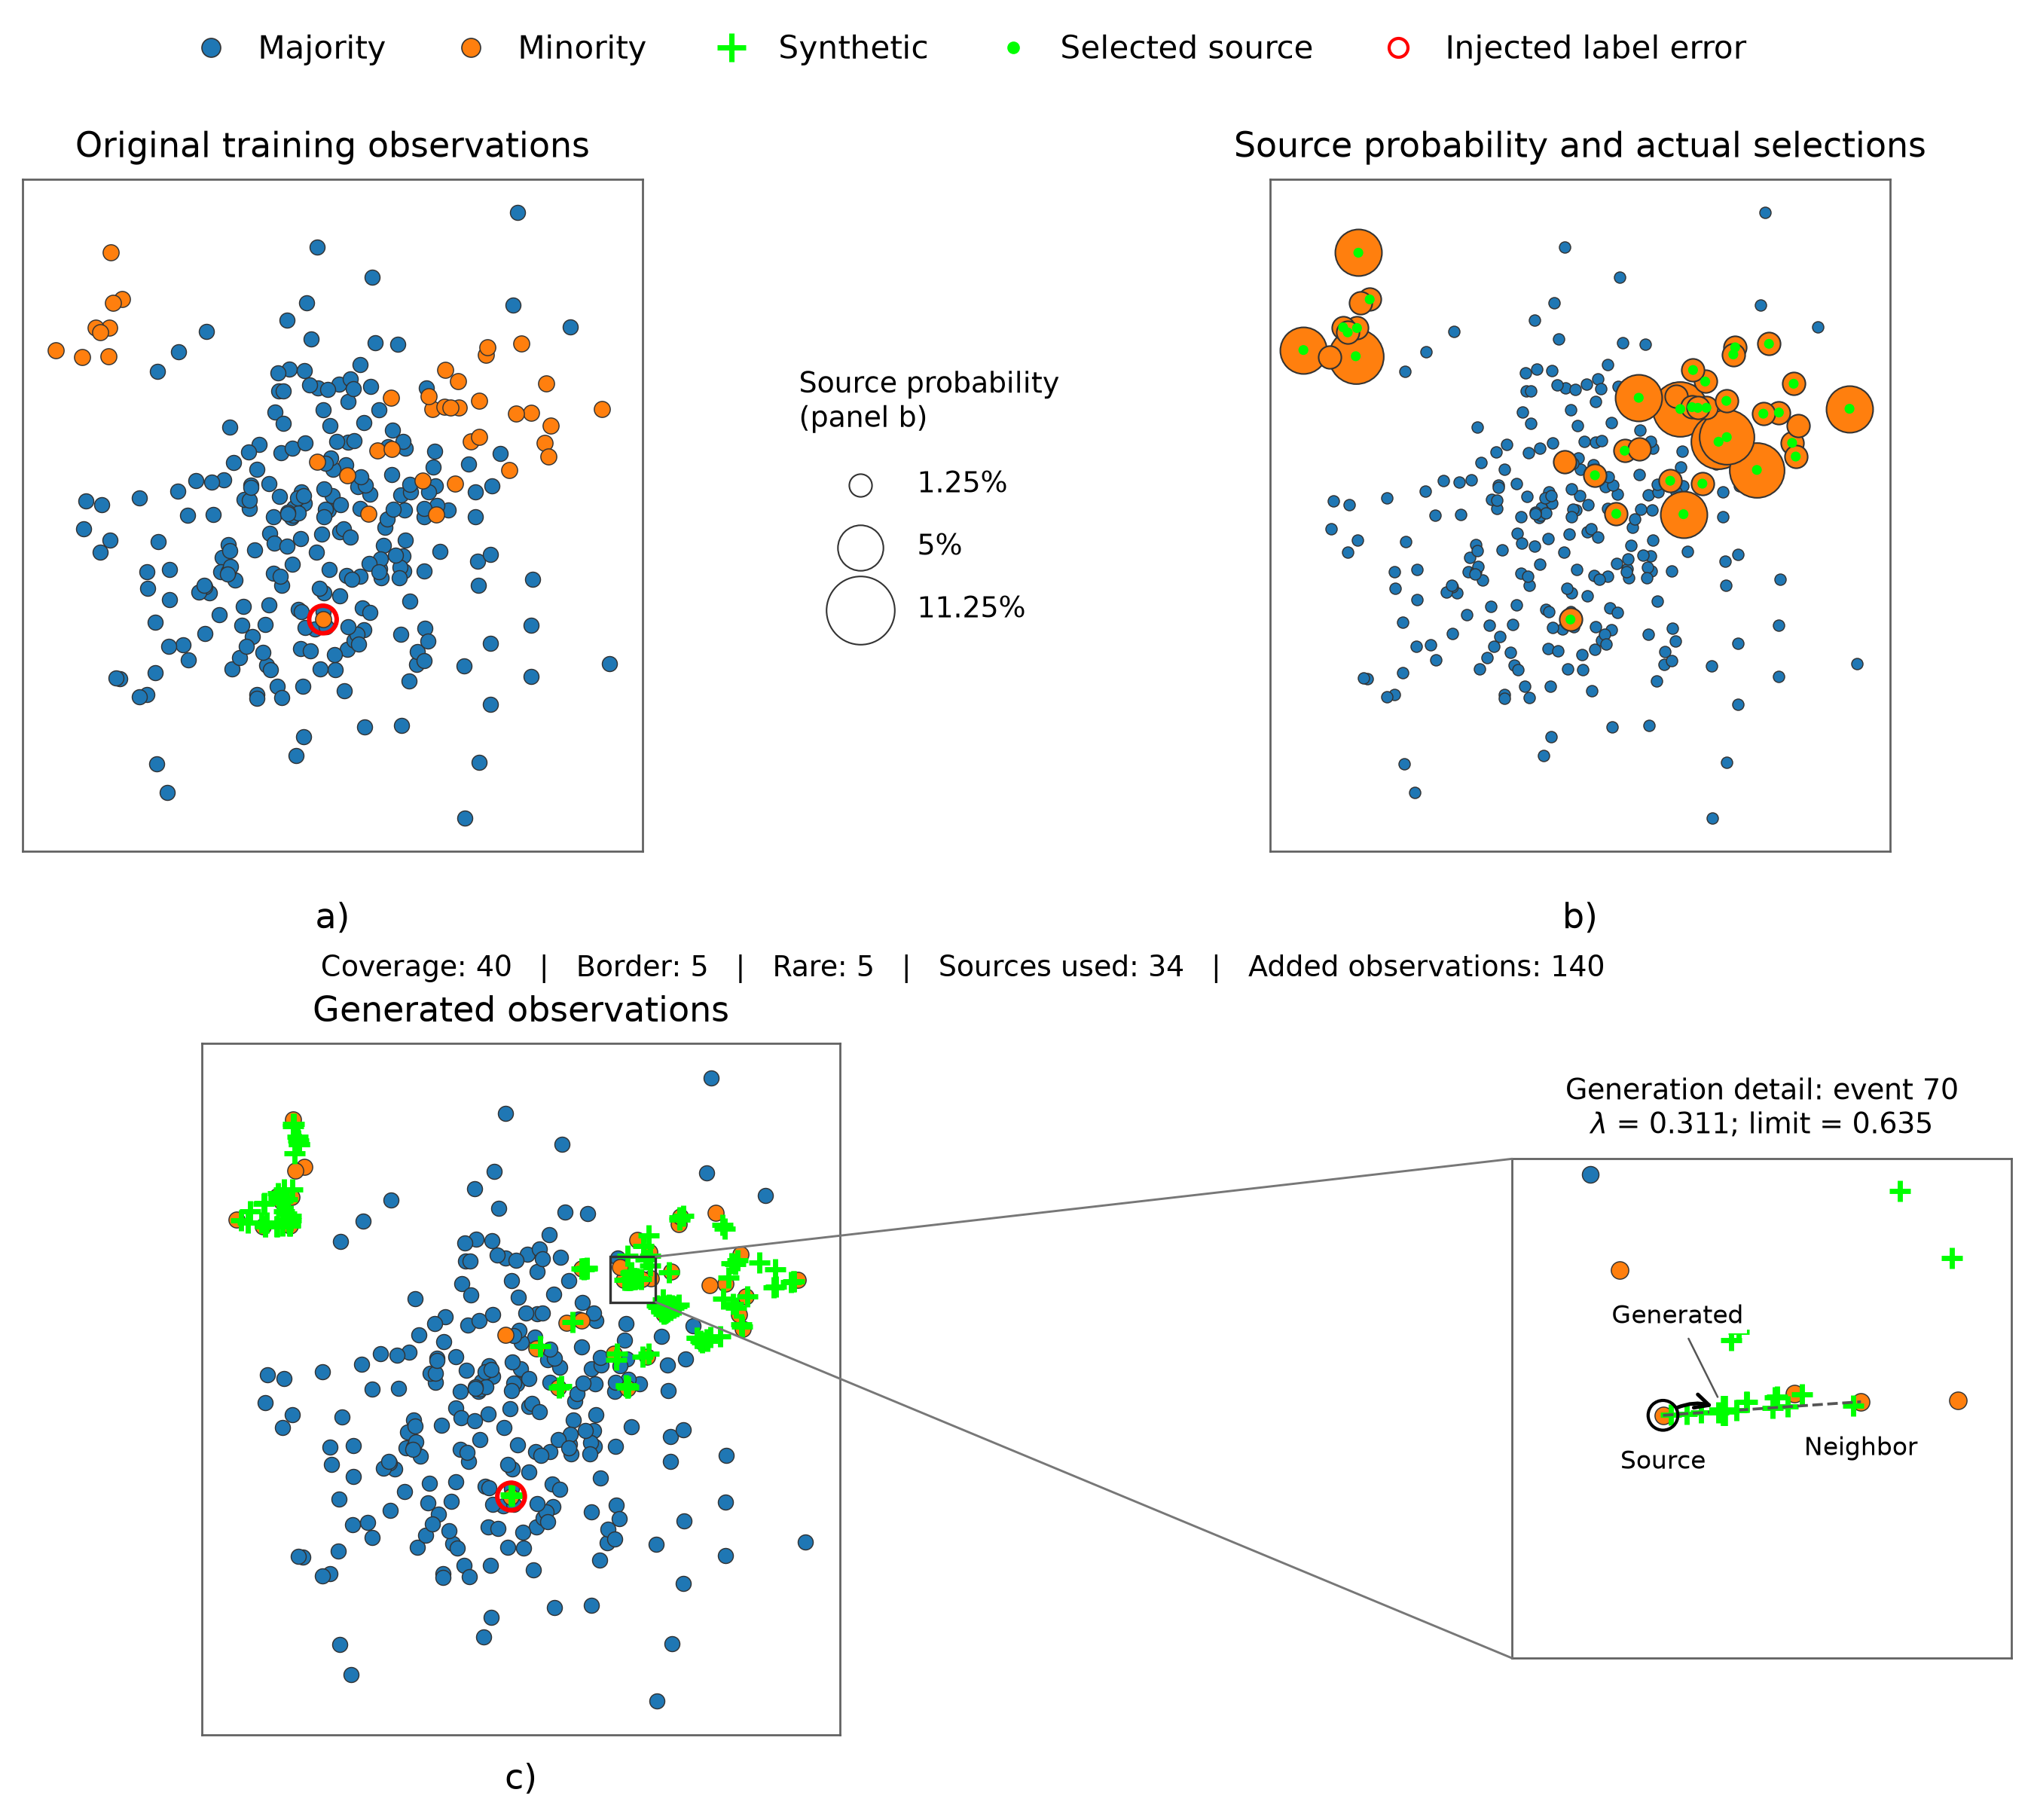

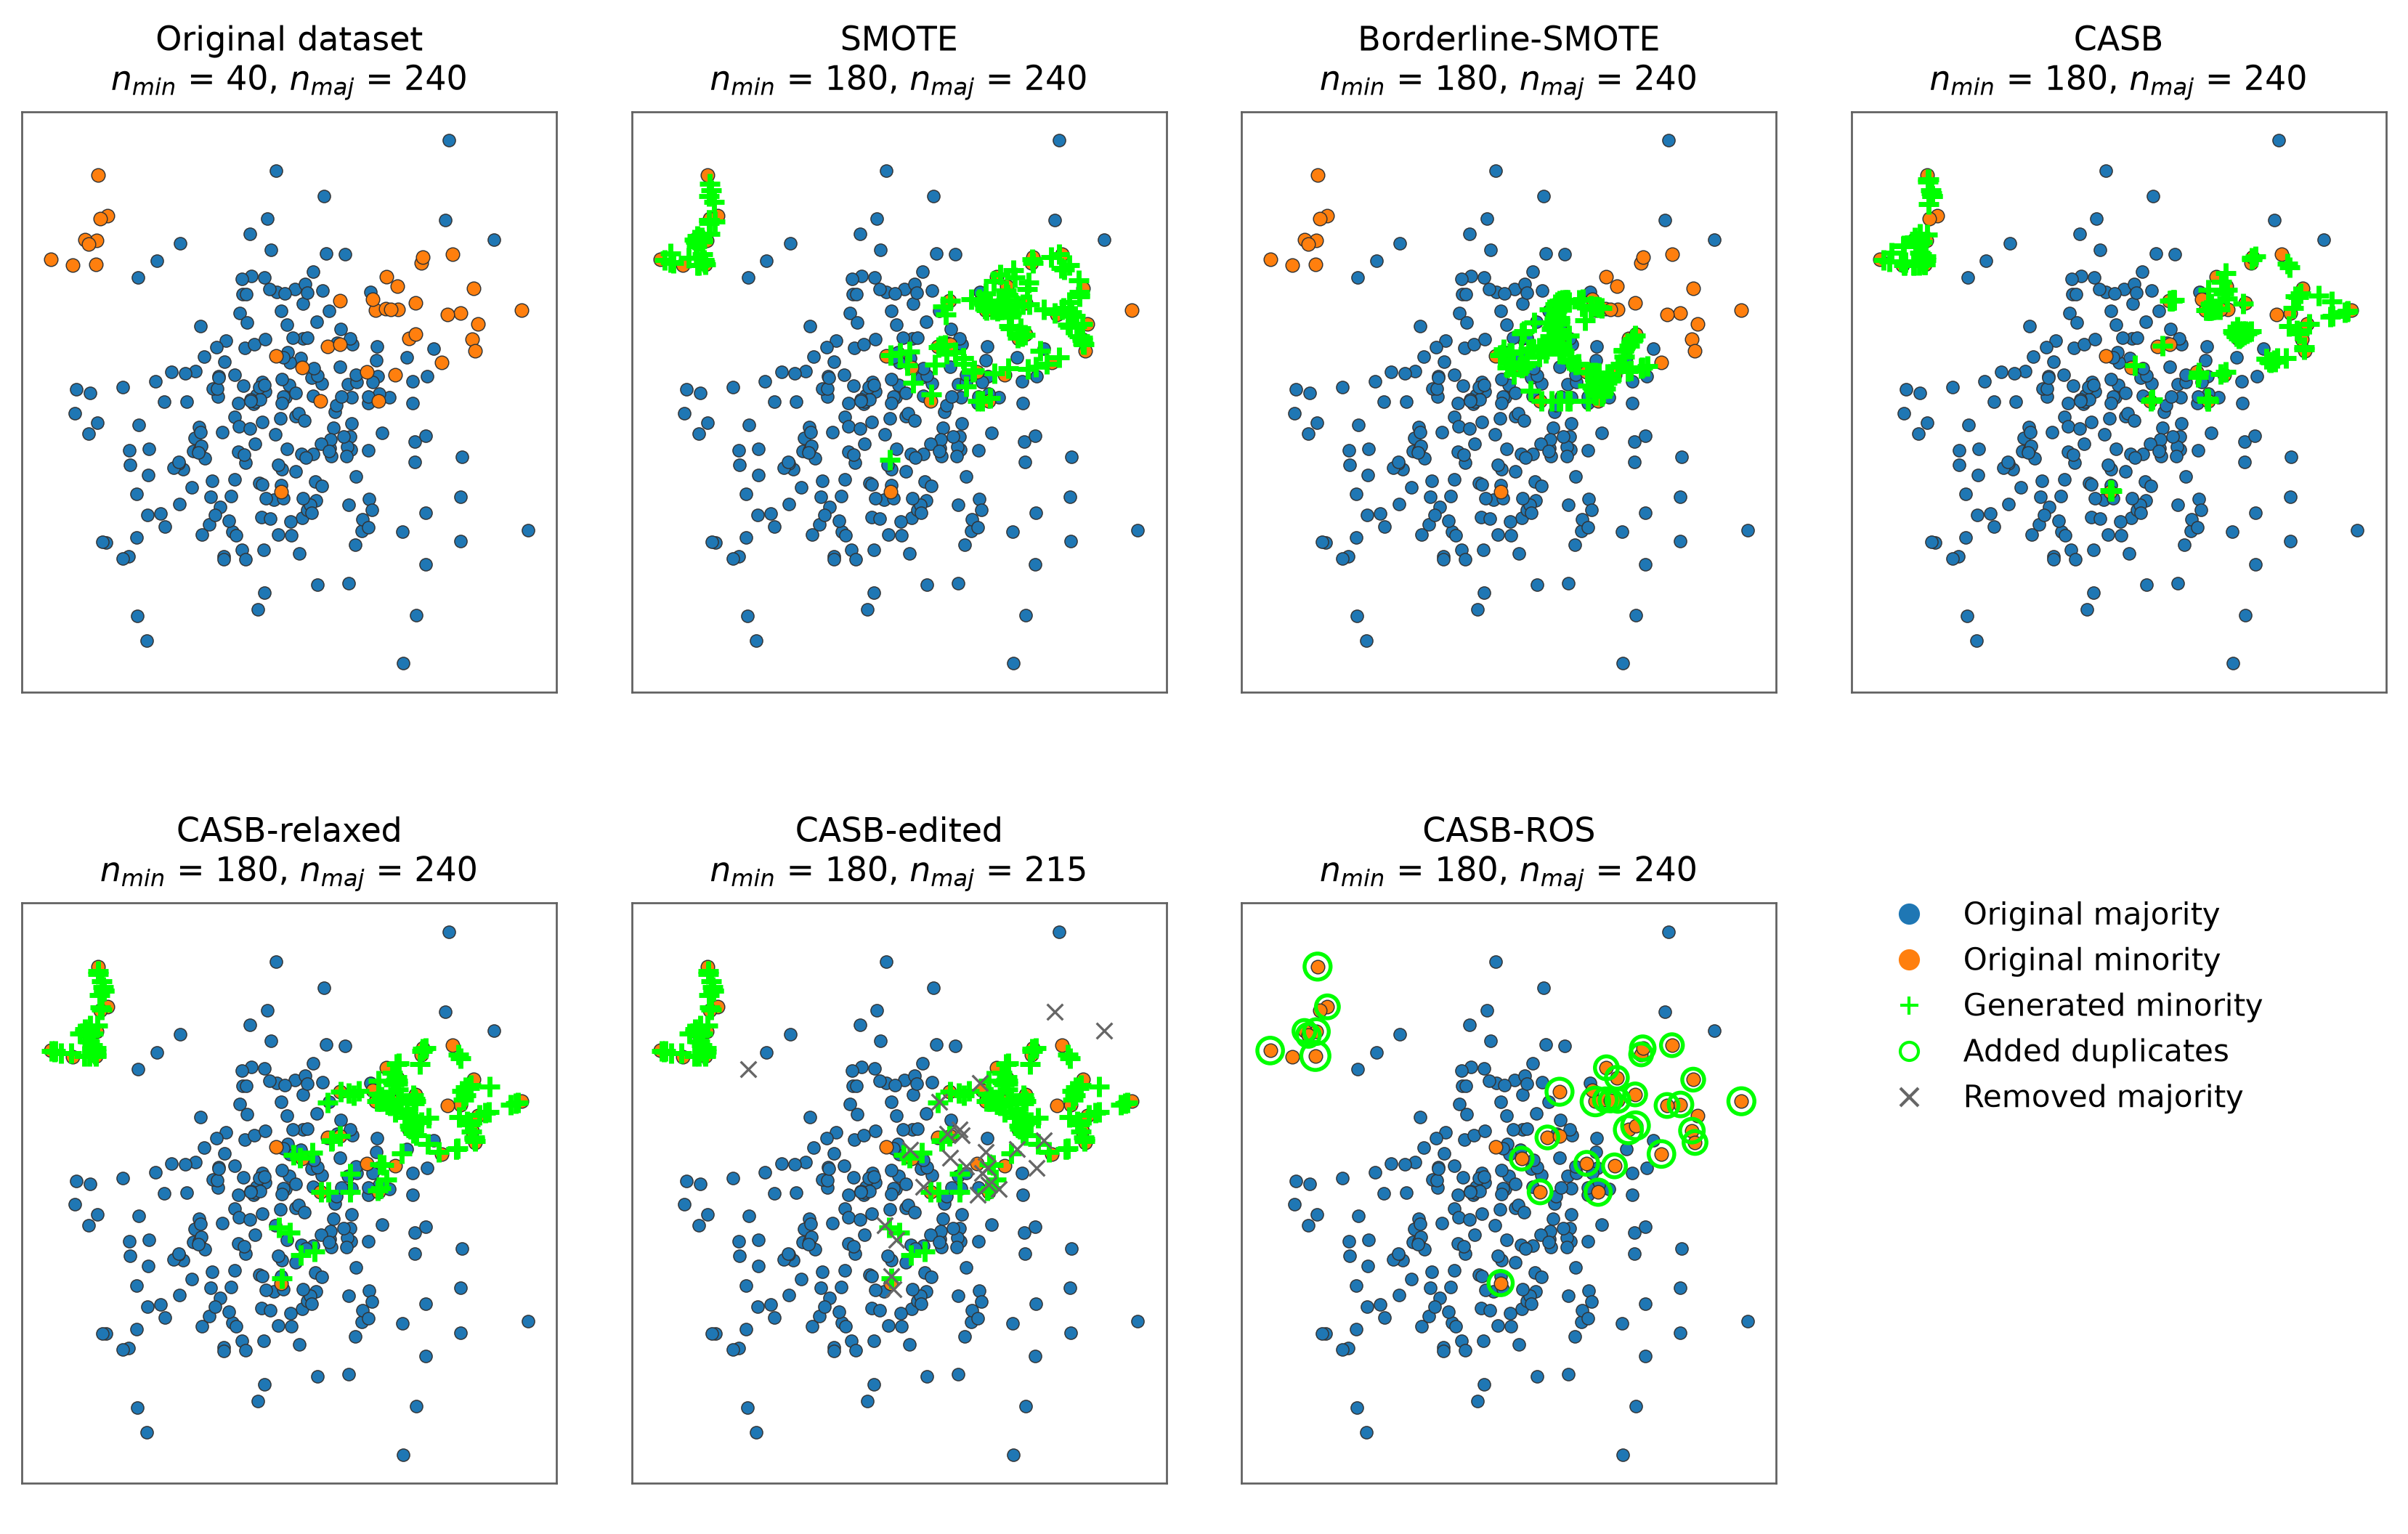

,scenario,method,generated,casb_from_injected_source
0,Separated classes,original,0,NaN
1,Separated classes,smote,268,NaN
2,Separated classes,casb,268,0.0
3,One injected label error,original,0,NaN
4,One injected label error,smote,266,NaN
5,One injected label error,casb,266,9.0
6,Curved minority structure,original,0,NaN
7,Curved minority structure,smote,276,NaN
8,Curved minority structure,casb,276,0.0


,method,added,removed,minority,majority
0,original,0,0,40,240
1,smote,140,0,180,240
2,bsmote,140,0,180,240
3,casb,140,0,180,240
4,casb_relaxed,140,0,180,240
5,casb_edited,140,25,180,215
6,casb_ros,140,0,180,240


,source_id,overlap,support,border,rare,selection_mass,selected_count
0,240,0.1,9,False,False,0.0125,1
1,241,0.0,10,False,False,0.0125,1
2,242,0.4,6,True,False,0.0725,11
3,243,0.3,7,True,False,0.0725,13
4,244,0.2,8,False,False,0.0125,0
5,245,0.1,9,False,False,0.0125,3
6,246,0.1,9,False,False,0.0125,2
7,247,0.1,9,False,False,0.0125,1
8,248,0.9,1,False,False,0.0125,1
9,249,1.0,0,False,False,0.0125,2


,source_id,neighbor_id,lambda_value,lambda_limit,overlap,same_support,majority_distance,branch,actual_branch,status
0,243,246,0.187085,0.426279,0.3,7,0.200571,coverage,coverage,accepted
1,257,250,0.697368,1.000000,0.1,9,0.387604,coverage,coverage,accepted
2,248,255,0.397416,0.407346,0.9,1,0.106071,coverage,coverage,accepted
3,269,255,0.081522,0.103709,1.0,0,0.096203,coverage,coverage,accepted
4,260,265,0.090118,0.200090,1.0,0,0.116455,coverage,coverage,accepted
...,...,...,...,...,...,...,...,...,...,...
135,270,278,0.174641,1.000000,0.2,8,0.933897,rare,rare,accepted
136,276,274,0.518357,0.876871,0.2,8,1.084337,rare,rare,accepted
137,267,243,0.055355,0.140626,0.8,2,0.155934,rare,rare,accepted
138,276,274,0.442404,0.876871,0.2,8,1.084337,rare,rare,accepted


Implementation SHA256: 3a06170892e0154b00dd73267af33ee41abea67e86d470c8c17e1140de838844
Toy input SHA256: 5088788de3096d451b07a86f6dad450fd839acc168097769c87300114521995e


Saved six original figures, caption notes, and six-page visual guide.


In [1]:
from pathlib import Path
import sys,json,hashlib
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle, Ellipse, Circle
from matplotlib.lines import Line2D
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from threadpoolctl import threadpool_limits
from IPython.display import Image,display
ROOT=Path.cwd()
if not (ROOT/'binary_oversampling.py').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from binary_oversampling import sampler,CASBSMOTE
guard=threadpool_limits(limits=1)
OUT=ROOT/'paper_material';OUT.mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.titlesize':12,'pdf.fonttype':42,'ps.fonttype':42,'svg.fonttype':'none'})
BLUE='#2474A8';ORANGE='#E78326';GREEN='#119C62';RED='#BD334A';PURPLE='#8154A4';NAVY='#1C344B';GRAY='#9AA7B1';PALE='#EDF3F7'
figures=[];captions=[]
def save(fig,stem,title,caption):
    for ext in ['png','pdf','svg']:fig.savefig(OUT/(stem+'.'+ext),dpi=300,bbox_inches='tight',facecolor='white')
    plt.close(fig);figures.append(stem);captions.append((title,caption))
    display(Image(filename=str(OUT/(stem+'.png')),width=1100))
def decorate(ax):
    ax.set_xticks([]);ax.set_yticks([])
    for s in ax.spines.values():s.set_color('#ADB6BE');s.set_linewidth(.7)
def cloud(ax,X,y,g=None,noise=None,alpha=.65,size=15):
    ax.scatter(*X[y==0].T,c=BLUE,s=size,alpha=alpha,linewidths=.2,edgecolors='white')
    ax.scatter(*X[y==1].T,c=ORANGE,s=size+6,alpha=.95,linewidths=.25,edgecolors='white',zorder=3)
    if g is not None and len(g):ax.scatter(*g.T,c=GREEN,s=27,marker='+',lw=1,alpha=.9,zorder=4)
    if noise is not None and len(noise):ax.scatter(*X[noise].T,facecolors='none',edgecolors=RED,s=86,lw=1.3,zorder=5)
    decorate(ax)
def legend(fig,noise=False):
    h=[Line2D([],[],marker='o',ls='',color=BLUE,label='Original majority'),Line2D([],[],marker='o',ls='',color=ORANGE,label='Original minority'),Line2D([],[],marker='+',ls='',color=GREEN,markersize=9,label='Generated minority')]
    if noise:h.append(Line2D([],[],marker='o',ls='',color=RED,markerfacecolor='none',label='Injected mislabeled point'))
    fig.legend(handles=h,loc='upper center',bbox_to_anchor=(.5,.925),ncol=4,frameon=False,fontsize=10)

# Independent illustrative datasets. Data are fixed, not searched for favorable images.
rng=np.random.default_rng(314)
maj=rng.normal([0,0],[.65,.52],(300,2));mins=rng.normal([2.5,1.25],[.38,.30],(32,2))
clean=np.vstack([maj,mins]);yc=np.r_[np.zeros(300,int),np.ones(32,int)]
noisy=clean.copy();yn=yc.copy();noise_ids=np.array([int(np.argmin(np.linalg.norm(maj-[.4,.15],axis=1)))]);yn[noise_ids]=1
t=np.linspace(.08,2*np.pi-.08,24);arcmin=np.c_[2*np.cos(t),2*np.sin(t)]+rng.normal(0,.035,(24,2))
t2=rng.uniform(0,2*np.pi,300);rad=rng.uniform(1.45,1.72,300);arcmaj=np.c_[rad*np.cos(t2),rad*np.sin(t2)]
curved=np.vstack([arcmaj,arcmin]);ya=np.r_[np.zeros(300,int),np.ones(24,int)]
datasets=[('Separated classes',clean,yc,[]),('One injected label error',noisy,yn,noise_ids),('Curved minority structure',curved,ya,[])]
fig,axs=plt.subplots(3,3,figsize=(13,10))
scenario_audit=[]
for r,(label,raw,y,noise) in enumerate(datasets):
    X=StandardScaler().fit_transform(raw)
    lo=X.min(0)-.25;hi=X.max(0)+.25
    for c,m in enumerate(['original','smote','casb']):
        s=sampler(m,y,42,1.0);xr,yr=(X,y) if s is None else s.fit_resample(X,y)
        g=xr[len(X):];ax=axs[r,c];cloud(ax,X,y,g,noise);ax.set(xlim=(lo[0],hi[0]),ylim=(lo[1],hi[1]))
        ax.set_title(f'({chr(97+r*3+c)}) '+['Original','SMOTE','CASB'][c]+f' | +{len(g)}')
        if c==0:ax.set_ylabel(label,fontsize=11,labelpad=12)
        from_noise=sum(a['source_id'] in noise for a in getattr(s,'audit_',[]))
        scenario_audit.append(dict(scenario=label,method=m,generated=len(g),casb_from_injected_source=from_noise if m=='casb' else None))
        if r==1 and c==2:ax.text(.02,.03,f'{from_noise} CASB samples originate from the injected point',transform=ax.transAxes,fontsize=8,bbox={'facecolor':'white','alpha':.85,'edgecolor':'none'})
fig.suptitle('Existing noise and curved geometry: what generation can change',fontsize=18,y=.985)
legend(fig,True);fig.subplots_adjust(top=.85,bottom=.06,wspace=.12,hspace=.25)
save(fig,'09_noise_and_geometry_panels','Noise and geometry before and after resampling',
 'Counterpart to the role of UGO Fig. 1. All plotted synthetic points are actual outputs of SMOTE and CASB on three fixed artificial datasets, independently constructed here. Each row uses one scaler fitted to its original observations, one seed (42), one target ratio (1.0), and common axes. Red circles identify a deliberately flipped majority label, known by construction; CASB did not detect it. The annotation counts accepted CASB audit records whose source is that injected point. Coverage can still propagate mislabeled minority observations. The curved example illustrates interpolation across a curved support, not a quantitative robustness result. No source-paper points or artwork are reused.')

def box(ax,x,y,w,h,text,fc=PALE,fs=8.5):
    p=FancyBboxPatch((x,y),w,h,boxstyle='round,pad=0.01,rounding_size=.018',fc=fc,ec=GRAY,lw=1)
    ax.add_patch(p);ax.text(x+w/2,y+h/2,text,ha='center',va='center',fontsize=fs,color=NAVY,linespacing=1.3)
def arrow(ax,start,end,rad=0,color=NAVY):
    ax.annotate('',xy=end,xytext=start,arrowprops={'arrowstyle':'-|>','lw':1.3,'color':color,'connectionstyle':f'arc3,rad={rad}','shrinkA':3,'shrinkB':3})
def cylinder(ax,x,y,w,h,label):
    ax.add_patch(Rectangle((x,y),w,h,facecolor=PALE,edgecolor=GRAY))
    ax.add_patch(Ellipse((x+w/2,y),w,h*.25,facecolor=PALE,edgecolor=GRAY))
    ax.add_patch(Ellipse((x+w/2,y+h),w,h*.25,facecolor='white',edgecolor=GRAY))
    ax.text(x+w/2,y+h*.50,label,ha='center',va='center',fontsize=10,color=NAVY)
fig,axs=plt.subplots(1,2,figsize=(14,10))
text_box_pairs=[]
for ax,title,stages in zip(axs,['(a) SMOTE','(b) CASB'],[
 ['Original training data', 'All minority observations\nare eligible source points', 'Sample a minority source\nChoose a nearby minority neighbor', 'Interpolate along the selected edge\n0 <= lambda <= 1', 'Original data + generated observations'],
 ['Original training data', 'Compute coverage / border / rare pools\nAllocate 50% / 30% / 20% of new samples', 'Sample a source from the assigned pool\nChoose a nearby minority neighbor', 'Apply the branch-specific step limit\nInterpolate along the selected edge', 'Original data + generated observations']]):
    ax.set(xlim=(0,1),ylim=(0,1));ax.axis('off');ax.set_title(title,fontsize=16,weight='bold',pad=15)
    ys=[.82,.64,.46,.28,.10]
    for i,(yy,label) in enumerate(zip(ys,stages)):
        rect=FancyBboxPatch((.06,yy),.73,.115,boxstyle='round,pad=0.008,rounding_size=.01',facecolor='white' if i in [0,4] else PALE,edgecolor=NAVY,linewidth=1)
        ax.add_patch(rect)
        tx=ax.text(.425,yy+.0575,label,ha='center',va='center',fontsize=11,color=NAVY,linespacing=1.5)
        text_box_pairs.append((rect,tx))
        if i:arrow(ax,(.425,ys[i-1]-.008),(.425,yy+.123))
    # Orthogonal count loop from generation back to source sampling.
    ax.plot([.80,.92,.92],[.3375,.3375,.5175],color=NAVY,lw=1.2)
    arrow(ax,(.92,.5175),(.80,.5175))
    ax.text(.955,.4275,'Repeat to fill quota' if title.endswith('CASB') else 'Repeat to reach target',rotation=90,ha='center',va='center',fontsize=9,color=NAVY)
fig.suptitle('Source selection and generation: SMOTE versus CASB',fontsize=21,y=.98)
fig.text(.5,.025,'The loop generates the requested number of observations. It does not retrain a classifier or estimate uncertainty.',ha='center',fontsize=11)
fig.subplots_adjust(top=.88,bottom=.08,wspace=.12)
fig.canvas.draw()
renderer=fig.canvas.get_renderer()
for rect,tx in text_box_pairs:
    rb=rect.get_window_extent(renderer);tb=tx.get_window_extent(renderer)
    assert rb.x0+3<tb.x0 and tb.x1<rb.x1-3 and rb.y0+3<tb.y0 and tb.y1<rb.y1-3,tx.get_text()
save(fig,'10_sampling_path_comparison','Sampling paths: SMOTE and CASB',
 'Side-by-side sampling diagrams for SMOTE and base CASB. Text is verified to fit within its box; arrows show processing order and a count-driven generation loop. CASB computes overlapping pools and allocates fixed quotas before drawing sources. An empty pool falls back to all minority sources while retaining its branch-dependent interpolation rule. Neighborhood geometry is computed once on original training observations. Ratio selection is performed separately by training-only validation. No classifier-uncertainty or synthetic relocation stage is implemented.')

# Page 6 counterpart: show CASB's actual control quantity, not fabricated uncertainty scores.
fig,axs=plt.subplots(2,3,figsize=(12,7))
cases=[('Safe coverage',.1,.5,1.),('Border source',.5,.5,.25),('Rare source',.3,.35,.175)]
for col,(title,overlap,c,cap) in enumerate(cases):
    for row in range(2):
        ax=axs[row,col];vals=[1,1] if row==0 else [1,cap]
        bars=ax.bar(['SMOTE','CASB'],vals,color=[ORANGE,GREEN],width=.48)
        for b,v in zip(bars,vals):ax.text(b.get_x()+b.get_width()/2,v+.04,f'{v:g}',ha='center',fontsize=12)
        ax.set_ylim(0,1.25);ax.set_yticks([0,.5,1]);ax.spines[['top','right']].set_visible(False)
        ax.set_title(title+f'\nmajority fraction = {overlap:g}')
        if col==0:ax.set_ylabel('Maximum lambda' if row else 'Selected edge length (normalized)')
        if row:ax.text(.5,-.27,'Unrestricted' if col==0 else f'min(1, {c:g} x 2 / 4)',ha='center',transform=ax.transAxes,fontsize=10)
fig.suptitle('Same candidate segment, different allowed interpolation range',fontsize=18)
fig.subplots_adjust(top=.84,bottom=.13,hspace=.62,wspace=.30)
save(fig,'11_generation_control_comparison','Generation-control examples',
 'Counterpart to the mechanics-comparison role of UGO Fig. 3 on page 6 (there is no Fig. 6 on that page). These are analytical examples, not classifier probability estimates or experimental measurements. For all three examples the candidate edge has physical length L=4 and nearest-majority distance d=2. The upper row uses edge length normalized by L, so both methods equal 1. The lower row shows lambda_max: safe coverage is unrestricted; border uses 0.5d/L; rare uses 0.35d/L. These are conditional cases, not a universal CASB cap. CASB-relaxed and CASB-edited set the range to 1; CASB-ROS generates copies at lambda=0.')

# Main worked example: actual pools, quotas, probabilities, audited source-to-sample trajectories.
rng=np.random.default_rng(42)
M=rng.normal([0,0],[.8,.65],(240,2))
m=np.vstack([rng.normal([1.25,.6],[.42,.32],(30,2)),rng.normal([-1.7,1.25],[.22,.20],(9,2)),[[.05,-.5]]])
raw=np.vstack([M,m]);y=np.r_[np.zeros(len(M),int),np.ones(len(m),int)]
X=StandardScaler().fit_transform(raw);ids=np.flatnonzero(y==1);minor=X[ids];major=X[y==0];injected=np.array([len(X)-1])
model=CASBSMOTE(ratio=.75,random_state=42);xr,yr=model.fit_resample(X,y);g=model.generated_;audit=pd.DataFrame(model.audit_)
nn=NearestNeighbors(n_neighbors=12).fit(X).kneighbors(minor,return_distance=False)
near=[r[r!=i][:10] for r,i in zip(nn,ids)]
overlap=np.array([np.mean(y[r]==0) for r in near]);support=np.array([np.sum(y[r]==1) for r in near])
mn=NearestNeighbors(n_neighbors=7).fit(minor).kneighbors(minor,return_distance=False)
mn=[r[r!=i][:5] for i,r in enumerate(mn)]
third=np.array([np.linalg.norm(minor[r]-minor[i],axis=1)[2] for i,r in enumerate(mn)])
d=NearestNeighbors(n_neighbors=1).fit(major).kneighbors(minor)[0].ravel()
border=(overlap>.2)&(overlap<=.7)&(support>=2)&(d>0);rare=(third>=np.quantile(third,.75))&(support>=2)&(d>0)
pools=[np.arange(len(minor)),np.flatnonzero(border),np.flatnonzero(rare)]
quota=np.array(model.diagnostics_['allocation']);prob=np.zeros(len(minor))
for pool,q in zip(pools,quota):
    if len(pool)==0:pool=pools[0]
    prob[pool]+=q/len(g)/len(pool)
assert np.isclose(prob.sum(),1)
counts=np.bincount(audit.source_id,minlength=len(X))[ids]
lo=X.min(0)-.3;hi=X.max(0)+.3
def mini(ax,stage):
    cloud(ax,X,y,g if stage=='generated' else None,size=8)
    if stage=='pools':
        ax.scatter(*minor[border].T,facecolors='none',edgecolors=PURPLE,s=58,lw=.8)
        ax.scatter(*minor[rare].T,facecolors='none',edgecolors=GREEN,s=85,lw=.8)
    if stage=='selected':ax.scatter(*minor[counts>0].T,facecolors='none',edgecolors=GREEN,s=35+counts[counts>0]*8,lw=.9)
    ax.set(xlim=(lo[0],hi[0]),ylim=(lo[1],hi[1]))

fig=plt.figure(figsize=(16,10));ax=fig.add_axes([0,0,1,1]);ax.set(xlim=(0,1),ylim=(0,1));ax.axis('off')
ax.text(.04,.95,'CASB generation: from training data to audited synthetic samples',fontsize=21,weight='bold',color=NAVY)
stages=[(.045,'1  Original training data','original'),(.36,'2  Compute overlapping pools','pools'),(.675,'3  Select sources within quotas','selected')]
for x,title,stage in stages:
    ax.add_patch(FancyBboxPatch((x,.56),.27,.30,boxstyle='round,pad=.008',fc=PALE,ec=GRAY))
    ax.text(x+.135,.83,title,ha='center',fontsize=12,weight='bold',color=NAVY)
    sub=fig.add_axes([x+.018,.585,.234,.21]);mini(sub,stage)
arrow(ax,(.32,.70),(.355,.70));arrow(ax,(.63,.70),(.67,.70))
ax.text(.18,.515,'Training-only scaling\n240 majority / 40 minority',ha='center',fontsize=11)
ax.text(.495,.515,f'Coverage: 40 | Border: {border.sum()} | Rare: {rare.sum()}\nPools overlap; coverage includes every minority point',ha='center',fontsize=10)
ax.text(.81,.515,f'Add {len(g)} samples at ratio 0.75\nBranch quotas: '+ ' / '.join(map(str,quota)),ha='center',fontsize=11)
box(ax,.675,.26,.27,.14,'4  Neighbor + generation rule\nChoose t among minority neighbors\nz = x_s + lambda (x_t - x_s)',fc='#F8EBD9',fs=11)
arrow(ax,(.81,.49),(.81,.40))
sub=fig.add_axes([.375,.17,.24,.23]);mini(sub,'generated');ax.text(.495,.425,'5  Append generated minority points',ha='center',fontsize=12,weight='bold')
arrow(ax,(.675,.33),(.625,.30))
box(ax,.045,.23,.27,.16,'6  Resampled training set\nBase CASB: retain all originals\nEdited path: majority-only ENN\nFit SVM, KNN, RF or LR\nEvaluate held-out observations',fc='#E3F0E9',fs=10)
arrow(ax,(.37,.29),(.32,.29))
ax.text(.50,.075,'Count-driven generation; geometry is computed on original training observations.\nNo uncertainty score, minority-noise filtering, or post-generation relocation is performed.',ha='center',fontsize=12,color=NAVY)
save(fig,'12_graphical_casb_process','Graphical CASB process with data panels',
 'Counterpart to the detailed process illustration in UGO Fig. 4. Every embedded point cloud comes from the same independently constructed example, transformed once using original training data. Border and rare membership and source multiplicities are computed from the implemented rules and audit records. The pictured generation is base CASB. The edited path uses unrestricted generation with different quotas before majority cleaning, not the capped cloud pictured here. The base CASB generation contains 50/30/20 percent quotas; relaxed/edited use 70/20/10 and unrestricted interpolation. No classifier or test set is used to manufacture the diagram. Arrows show processing order rather than an uncertainty-driven retraining loop.')

# Reference-inspired palette: solid blue/orange circles with dark outlines,
# bright green generated/selected points, and red known-label-error rings.
# Styling only: preserve the input, sampler, seed, ratio, and point coordinates.
PBLUE='#1f77b4';PORANGE='#ff7f0e';PGREEN='#00ff00';PRED='#ff0000';PEDGE='#333333'
def paper_axes(ax):
    ax.set_xticks([]);ax.set_yticks([])
    ax.set_aspect('equal',adjustable='box')
    for spine in ax.spines.values():spine.set_color('#606060');spine.set_linewidth(.65)

def paper_cloud(ax,xx,yy,generated=None,noise=None,size=23):
    ax.scatter(*xx[yy==0].T,c=PBLUE,s=size,edgecolors=PEDGE,linewidths=.35,zorder=2)
    ax.scatter(*xx[yy==1].T,c=PORANGE,s=size+3,edgecolors=PEDGE,linewidths=.35,zorder=3)
    if generated is not None and len(generated):
        ax.scatter(*generated.T,c=PGREEN,s=48,marker='+',linewidths=1.65,zorder=4)
    if noise is not None and len(noise):
        ax.scatter(*xx[noise].T,facecolors='none',edgecolors=PRED,s=77,linewidths=1.45,zorder=6)
    paper_axes(ax)

fig=plt.figure(figsize=(11.5,8.5))
a=fig.add_axes([.055,.55,.405,.35]);b=fig.add_axes([.535,.55,.405,.35])
c=fig.add_axes([.055,.09,.55,.36]);ins=fig.add_axes([.67,.13,.275,.26])
paper_cloud(a,X,y,noise=injected)
paper_cloud(b,X,y,size=13)
# Only minority points have a CASB source probability; no fabricated majority weights.
mass_scale=4200
for j in np.argsort(-prob):
    b.scatter(*minor[j],s=mass_scale*prob[j],c=PORANGE,edgecolors=PEDGE,linewidths=.5,zorder=3)
b.scatter(*minor[counts>0].T,s=10,c=PGREEN,edgecolors='none',zorder=5)
paper_cloud(c,X,y,g,noise=injected)
for ax in [a,b,c]:ax.set(xlim=(lo[0],hi[0]),ylim=(lo[1],hi[1]))
a.set_title('Original training observations',fontsize=11,pad=7)
b.set_title('Source probability and actual selections',fontsize=11,pad=7)
c.set_title('Generated observations',fontsize=11,pad=7)
for ax,tag in [(a,'a'),(b,'b'),(c,'c')]:
    ax.text(.5,-.04 if tag=='c' else -.075,tag+')',transform=ax.transAxes,ha='center',va='top',fontsize=11)
# Numerical source probabilities, not model uncertainty, drive bubble areas.
mass_key=[.0125,.05,.1125]
mass_handles=[plt.scatter([],[],s=mass_scale*v,facecolors='white',edgecolors=PEDGE,linewidths=.5,label=f'{100*v:g}%') for v in mass_key]
fig.legend(handles=mass_handles,title='Source probability\n(panel b)',loc='center',
         bbox_to_anchor=(.487,.735),frameon=False,fontsize=9,title_fontsize=9,
         labelspacing=1.2,borderpad=.7,handletextpad=1.0)
fig.text(.5,.485,f'Coverage: {len(minor)}   |   Border: {border.sum()}   |   Rare: {rare.sum()}   |   '
         f'Sources used: {sum(counts>0)}   |   Added observations: {len(g)}',ha='center',fontsize=9)
candidate=audit[(audit.branch=='border')&(audit.lambda_limit<.95)&(audit.lambda_value>0)]
if candidate.empty:candidate=audit[audit.lambda_value>0]
event_idx=int(candidate.index[0]);ev=audit.loc[event_idx];src=int(ev.source_id);tgt=int(ev.neighbor_id);z=g[event_idx]
assert np.allclose(z,X[src]+ev.lambda_value*(X[tgt]-X[src]))
# Zoom the first qualifying audited border event; never choose a flattering outcome.
edge=X[[src,tgt]];pad=max(np.linalg.norm(edge[1]-edge[0])*.4,.12)
mins=np.minimum(edge.min(0),z)-pad;maxs=np.maximum(edge.max(0),z)+pad
# Preserve aspect in the zoom while showing context around the full selected edge.
span=max(maxs-mins);center=(mins+maxs)/2
mins=center-span/2;maxs=center+span/2
paper_cloud(ins,X,y,g,size=28)
ins.set(xlim=(mins[0],maxs[0]),ylim=(mins[1],maxs[1]))
ins.plot(*edge.T,'--',color='#555555',lw=.9,zorder=5)
ins.scatter(*X[src],s=90,facecolors='none',edgecolors='black',lw=1.0,zorder=7)
ins.scatter(*z,s=90,marker='+',color=PGREEN,lw=2.3,zorder=8)
ins.annotate('',xy=z,xytext=X[src],arrowprops={'arrowstyle':'->','color':'black','lw':1.2,'connectionstyle':'arc3,rad=-.3','shrinkA':5,'shrinkB':4},zorder=9)
ins.annotate('Source',X[src],xytext=(0,-17),textcoords='offset points',ha='center',fontsize=8)
ins.annotate('Neighbor',X[tgt],xytext=(0,-17),textcoords='offset points',ha='center',fontsize=8)
ins.annotate('Generated',z,xytext=(-15,28),textcoords='offset points',ha='center',fontsize=8,
             bbox={'fc':'white','ec':'none','pad':1.2},
             arrowprops={'arrowstyle':'-','color':'#555555','lw':.6,'shrinkB':5},zorder=10)
ins.set_title(f'Generation detail: event {event_idx}\n'+r'$\lambda$'+f' = {ev.lambda_value:.3f}; limit = {ev.lambda_limit:.3f}',fontsize=9,pad=8)
# Connect corners explicitly so connector lines stay outside the zoom panel.
from matplotlib.patches import ConnectionPatch
c.add_patch(Rectangle(mins,*(maxs-mins),fill=False,ec='#333333',lw=.8,zorder=6))
for yy,corner in [(mins[1],(0,0)),(maxs[1],(0,1))]:
    fig.add_artist(ConnectionPatch(xyA=(maxs[0],yy),coordsA=c.transData,
                    xyB=corner,coordsB=ins.transAxes,color='#777777',lw=.7,zorder=1))
fig.legend(handles=[
    Line2D([],[],marker='o',ls='',color=PBLUE,markeredgecolor=PEDGE,markeredgewidth=.4,label='Majority'),
    Line2D([],[],marker='o',ls='',color=PORANGE,markeredgecolor=PEDGE,markeredgewidth=.4,label='Minority'),
    Line2D([],[],marker='+',ls='',color=PGREEN,markeredgewidth=1.7,markersize=9,label='Synthetic'),
    Line2D([],[],marker='o',ls='',color=PGREEN,markersize=3,label='Selected source'),
    Line2D([],[],marker='o',ls='',markerfacecolor='none',color=PRED,label='Injected label error')],
    loc='upper center',bbox_to_anchor=(.5,.99),ncol=5,frameon=False,fontsize=10,columnspacing=1.7,handletextpad=.5)

display(pd.DataFrame([{'zoom_event':event_idx,'source_id':src,'neighbor_id':tgt,
                      'lambda':ev.lambda_value,'lambda_limit':ev.lambda_limit}]))
save(fig,'13_audited_generation_walkthrough','Audited generation walkthrough',
 'Style inspired by UGO Fig. 5: opaque blue/orange observations with thin dark outlines, bright green synthetic points, and a linked magnified view. All coordinates and outputs are independently computed using the unchanged 240/40 artificial example, seed 42 and ratio 0.75. Panels show (a) original data, (b) source probabilities and actual selections, and (c) generated points. Bubble area equals 4200 times the minority source probability; majority marker size is fixed. A source probability sums (integer branch quota / total generated) / pool size over its pools. Green centers mark sources used at least once. The red ring marks a deliberately injected label error, not a CASB noise detection. The zoom shows the first positive-step, capped border audit event (zero-based index); the source-neighbor-lambda identity is numerically verified. The curved black arrow connects the recorded source to the actual generated point; the actual interpolation path is straight. There is no noise relocation or post-generation correction. Equal axis scaling prevents geometric distortion.')

fig,axs=plt.subplots(2,4,figsize=(14,8),sharex=True,sharey=True)
outaudit=[]
for ax,name,title in zip(axs.flat,['original','smote','bsmote','casb','casb_relaxed','casb_edited','casb_ros'],['Original dataset','SMOTE','Borderline-SMOTE','CASB','CASB-relaxed','CASB-edited','CASB-ROS']):
    s=sampler(name,y,42,.75)
    res,labels=(X.copy(),y.copy()) if s is None else s.fit_resample(X,y)
    removed=np.asarray(getattr(s,'removed_indices_',[]),int);keep=np.ones(len(y),bool);keep[removed]=False
    generated=s.generator_.generated_ if name=='casb_edited' else res[len(X):]
    paper_cloud(ax,X[keep],y[keep],None if name=='casb_ros' else generated,size=17)
    if name=='casb_ros':
        unique,count=np.unique(generated,axis=0,return_counts=True);ax.scatter(*unique.T,facecolors='none',edgecolors=PGREEN,s=40+12*np.sqrt(count),lw=1.3,zorder=5)
    if len(removed):ax.scatter(*X[removed].T,marker='x',color='#666666',s=27,lw=.8,zorder=5)
    ax.set_title(title+f'\n'+r'$n_{min}$'+f' = {sum(labels==1)}, '+r'$n_{maj}$'+f' = {sum(labels==0)}',fontsize=11,pad=7)
    ax.set(xlim=(lo[0],hi[0]),ylim=(lo[1],hi[1]))
    outaudit.append(dict(method=name,added=len(generated),removed=len(removed),minority=int(sum(labels==1)),majority=int(sum(labels==0))))
key=axs.flat[-1];key.axis('off')
key.legend(handles=[Line2D([],[],marker=mk,ls='',color=col,markerfacecolor='none' if label=='Added duplicates' else col,label=label) for mk,col,label in [('o',PBLUE,'Original majority'),('o',PORANGE,'Original minority'),('+',PGREEN,'Generated minority'),('o',PGREEN,'Added duplicates'),('x','#666666','Removed majority')]],loc='upper left',frameon=False,fontsize=10)
fig.subplots_adjust(top=.91,bottom=.09,wspace=.14,hspace=.24)
save(fig,'14_final_distribution_panels','Original and final resampled distributions',
 'The first panel shows the original independently constructed two-dimensional example: 240 majority and 40 minority observations, including one deliberately injected minority label error. This is not a named KEEL dataset. The next six panels show actual outputs on exactly the same data and equally scaled axes, at ratio 0.75 and seed 42. The palette and opaque outlined points follow the visual style of UGO Fig. 6; its artwork or data are not reused. CASB-edited removes only majority observations via three-neighbor majority-vote ENN. Removed points are shown as gray reference crosses, not retained observations. CASB-ROS duplicate multiplicities are shown with green ring sizes. This mechanism illustration is separate from benchmark scores and from the controlled overlap simulation.')

display(pd.DataFrame(scenario_audit));display(pd.DataFrame(outaudit))
display(pd.DataFrame({'source_id':ids,'overlap':overlap,'support':support,'border':border,'rare':rare,'selection_mass':prob,'selected_count':counts}))
display(audit)
print('Implementation SHA256:',hashlib.sha256((ROOT/'binary_oversampling.py').read_bytes()).hexdigest())
print('Toy input SHA256:',hashlib.sha256(X.tobytes()+y.tobytes()).hexdigest())
notes='''# Visual mechanism figures: response to the UGO page references

These original diagrams focus on point clouds and audited generation, rather than primarily generic flowcharts. They were made with code and the existing CASB implementation. No watermark is added; citations and scientific labels are retained. Each figure is supplied as PNG, PDF and editable SVG. The notebook is executed and includes source-pool membership, source probabilities, actual source multiplicities, and per-generated-point audits.

## Reference mapping

| Requested reference | New counterpart |
|---|---|
| Page 2, Fig. 1 | 09: three original / SMOTE / CASB noise-and-geometry scenarios |
| Page 5, Fig. 2 | 10: side-by-side sampling paths with data stores and count loops |
| Page 6 (actually Fig. 3) | 11: quantitative interpolation-control examples |
| Page 7, Fig. 4 | 12: graphical end-to-end process with embedded point clouds |
| Page 9, Fig. 5 | 13: original data, size-coded source mass, selected points and audited zoom |
| Fig. 6 (actually page 9) | 14: final distributions across six resampling methods |

UGO source: Saglam and Cengiz (2026), Uncertainty guided oversampling: A classifier-specific approach for effective handling of class imbalance in machine learning, Knowledge-Based Systems 342, 115886, https://doi.org/10.1016/j.knosys.2026.115886 . The diagrams are independent CASB illustrations, not reproductions of UGO artwork or claims that CASB implements UGO mechanisms. CASB does not have uncertainty-driven retraining, explicit minority-noise prefiltering or synthetic-point relocation.

## Can CASB have plots like UGO Figs. 10 and 11?

The controlled overlap experiment has now been executed in CASB_Overlap_Experiment.ipynb. Figures 15-20 and CASB_Overlap_Performance_Curves.pdf show IAM, MCC, G-mean, F1, precision and recall for SVM, KNN, RF and LR over 20 independent seeds and 11 class-center separations. Of 7920 attempted evaluations, 7912 succeeded; eight ADASYN failures are retained in the notebook. Incomplete method/distance/classifier cells are omitted from the curves. The horizontal axis varies geometric overlap, not label-corruption percentage. Training-only validation selects sampling ratios; test labels do not select a method or ratio. See Overlap_Experiment_Notes.md for the executed protocol and limitations. This is a related CASB simulation, not a numerical replication of UGO.

Separately test label-noise robustness at fixed separation, using declared corruption levels (for example 0%, 5%, 10%, 20%, 30%) on training labels only and a clean held-out test set. This isolates label corruption from geometric overlap. Do not infer noise removal from visually compact clouds. Report all variants, including deterioration; the method may still resample mislabeled coverage sources.

Figures 13 and 14 use the same independently generated 240/40 example and actual sampler outputs as before their style revision. Their opaque blue/orange points, dark outlines and bright green generated markers are inspired by the reference palette. Equal axis scaling preserves the geometry. This is an illustrative artificial dataset, not real-world benchmark data.

'''
notes+='\n'.join(f'## {title}\n\n{caption}\n' for title,caption in captions)
(OUT/'Visual_Mechanism_Captions.md').write_text(notes,encoding='utf8')

from reportlab.pdfgen import canvas
from reportlab.lib.utils import ImageReader
from reportlab.platypus import Paragraph
from reportlab.lib.styles import ParagraphStyle
from xml.sax.saxutils import escape
from PIL import Image as PILImage
c=canvas.Canvas(str(OUT/'CASB_Visual_Mechanisms.pdf'),pagesize=(1000,850));c.setTitle('CASB Visual Mechanisms');c.setAuthor('')
style=ParagraphStyle('caption',fontName='Helvetica',fontSize=11,leading=15)
for i,(stem,(title,caption)) in enumerate(zip(figures,captions),1):
    c.setFont('Helvetica-Bold',17);c.drawString(36,818,title)
    im=PILImage.open(OUT/(stem+'.png'));w,h=im.size;scale=min(928/w,590/h);dw,dh=w*scale,h*scale
    c.drawImage(ImageReader(im),(1000-dw)/2,204+(590-dh)/2,width=dw,height=dh)
    p=Paragraph(escape(caption),style);_,ph=p.wrap(928,170);assert ph<=170,(stem,ph);p.drawOn(c,36,184-ph)
    c.setFont('Helvetica',9);c.drawRightString(964,18,str(i));c.showPage()
c.save();print('Saved six original figures, caption notes, and six-page visual guide.')
